In [1]:
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

In [2]:
JSONL_PATH = "./train_data/vlm_val.jsonl"
INDEX = 0

def load_jsonl(path):
    with open(path, "r", encoding='utf-8') as f:
        return [json.loads(line) for line in f]
    
def find_user_and_assistant(sample):
    user_text = ""
    image_path = None
    assistance_text = ""
    
    for msg in sample["messages"]:
        if msg["role"] == "user":
            for item in msg["content"]:
                if item["type"] == "text":
                    user_text = item["text"]
                elif item["type"] == "image":
                    image_path = item["image"]

        elif msg["role"] == "assistant":                
             for item in msg["content"]:
                if item["type"] == "text":
                    assistance_text = item["text"]
                    
    return user_text, image_path, assistance_text

In [6]:
# Let's test persing

idx = 2000
data = load_jsonl(JSONL_PATH)
sample = data[idx]

user_text, image_path, assistance_text = find_user_and_assistant(sample)
print("User Text:", user_text)
print("Assistance Text:", assistance_text)
print("Image Path:", image_path)

User Text: show me all sink in this floor plan
Assistance Text: {"class":"Sink","count":1,"polygons":[[[377.0,129.0],[440.0,129.0],[440.0,172.0],[377.0,172.0]]],"present":true}
Image Path: ./raw_data/images/TR_D_00128.PNG


In [7]:
import json
import re

def try_parse_json(text):
    if not text:
        return None

    text = text.strip()

    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass

    match = re.search(r"\{.*", text, flags=re.DOTALL)
    if not match:
        return None

    candidate = match.group(0).strip()

    open_curly = candidate.count("{")
    close_curly = candidate.count("}")
    open_square = candidate.count("[")
    close_square = candidate.count("]")

    if close_square < open_square:
        candidate += "]" * (open_square - close_square)
    if close_curly < open_curly:
        candidate += "}" * (open_curly - close_curly)

    try:
        return json.loads(candidate)
    except json.JSONDecodeError:
        return None


parsed_assistance = try_parse_json(assistance_text)
if parsed_assistance is not None:
    print("Parsed Assistance Text as JSON:", parsed_assistance)
else:
    print("Assistance Text is not valid JSON.")


Parsed Assistance Text as JSON: {'class': 'Sink', 'count': 1, 'polygons': [[[377.0, 129.0], [440.0, 129.0], [440.0, 172.0], [377.0, 172.0]]], 'present': True}


User Question:
do you find any air room here

Assistant Reply:
Image Path: ./raw_data/images/TR_D_00061.PNG
{"answer":"There are 1 air room."}
No polygons found in assistant reply.


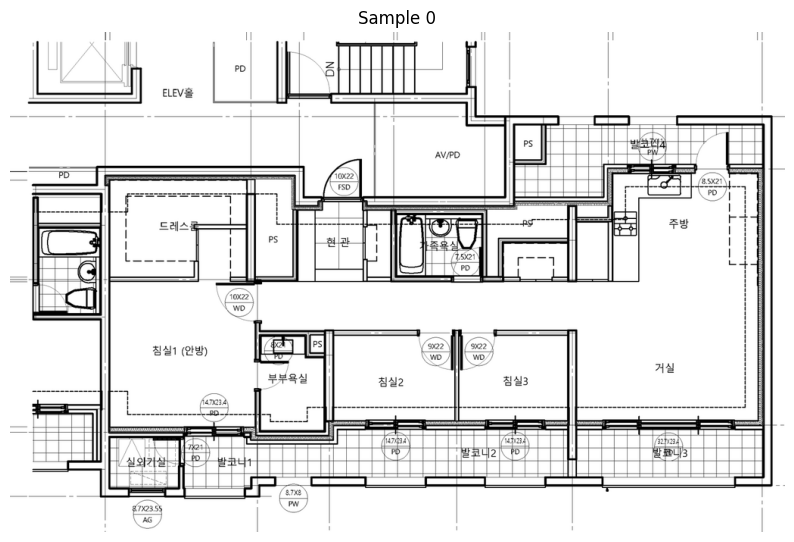

In [9]:
import hashlib # For consistent color generation


idx = 3000


def get_color_for_label(label):
    # Generate a consistent color from label string
    hash_object = hashlib.md5(label.encode()).hexdigest()
    return tuple(int(hash_object[i:i+2], 16) for i in (0, 2, 4)) # Unique color based on unlimited labels


def looks_like_point_list(poly):
    return (
        isinstance(poly, list)
        and len(poly) >= 3
        and all(isinstance(p, (list, tuple)) and len(p) == 2 for p in poly)
    )

def collect_polygons_dynamic(data, current_label="Unknown"):
    items = []

    if isinstance(data, dict):
        next_label = current_label

        for key in ["class", "label", "name", "category", "room_type"]:
            if key in data and isinstance(data[key], str):
                next_label = data[key]
                break

        for key, value in data.items():
            key_lower = str(key).lower()

            if key_lower in ["polygon", "points", "coordinates"] and looks_like_point_list(value):
                items.append((next_label, value))

            elif key_lower in ["polygons", "boxes", "segments", "shapes"] and isinstance(value, list):
                for poly in value:
                    if looks_like_point_list(poly):
                        items.append((next_label, poly))
                    else:
                        items.extend(collect_polygons_dynamic(poly, next_label))

            elif isinstance(value, (dict, list)):
                items.extend(collect_polygons_dynamic(value, next_label))

    elif isinstance(data, list):
        for item in data:
            items.extend(collect_polygons_dynamic(item, current_label))

    return items

def draw_polygons_if_present(image, payload):
    if not isinstance(payload, (dict, list)):
        print("No valid JSON payload found.")
        return image

    draw = ImageDraw.Draw(image)
    polygon_items = collect_polygons_dynamic(payload)

    if not polygon_items:
        print("No polygons found in assistant reply.")
        return image

    for label, poly in polygon_items:
        color = get_color_for_label(label)
        pts = [tuple(p) for p in poly]
        draw.polygon(pts, outline=color, width=4)

    return image



samples = load_jsonl(JSONL_PATH)
sample = samples[idx]

user_text, image_path, assistant_text = find_user_and_assistant(sample)

print("User Question:")
print(user_text)
print("\nAssistant Reply:")
print("Image Path:", image_path)
print(assistant_text)

img = Image.open(image_path).convert("RGB")
payload = try_parse_json(assistant_text)
img_vis = draw_polygons_if_present(img.copy(), payload)

plt.figure(figsize=(10, 10))
plt.imshow(img_vis)
plt.axis("off")
plt.title(f"Sample {INDEX}")
plt.show()
    

In [65]:
def sample_has_polygons(sample):
    _, _, assistant_text = find_user_and_assistant(sample)
    payload = try_parse_json(assistant_text)
    if not isinstance(payload, (dict, list)):
        return False
    found = collect_polygons_dynamic(payload)
    return len(found) > 0

polygon_indices = [i for i, s in enumerate(samples) if sample_has_polygons(s)]
print("First polygon sample indices:", polygon_indices[:20])


First polygon sample indices: [2, 5, 6, 9, 10, 13, 14, 17, 22, 26, 28, 29, 30, 33, 42, 44, 46, 47, 50, 54]


In [63]:
import json

JSONL_PATH = "./train_data/vlm_val.jsonl"

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

def find_user_and_assistant(sample):
    user_text = ""
    image_path = None
    assistant_text = ""

    for msg in sample["messages"]:
        if msg["role"] == "user":
            for item in msg["content"]:
                if item["type"] == "text":
                    user_text = item["text"]
                elif item["type"] == "image":
                    image_path = item["image"]
        elif msg["role"] == "assistant":
            for item in msg["content"]:
                if item["type"] == "text":
                    assistant_text = item["text"]

    return user_text, image_path, assistant_text

keywords = ["adjacent", "next to", "neighbor", "connected", "relation", "room connections"]

samples = load_jsonl(JSONL_PATH)
matches = []

for i, sample in enumerate(samples):
    user_text, image_path, assistant_text = find_user_and_assistant(sample)
    text = user_text.lower()
    if any(k in text for k in keywords):
        matches.append((i, user_text, image_path, assistant_text))

print(f"Found {len(matches)} relation-related samples\n")

for idx, question, image_path, answer in matches[:20]:
    print(f"Index: {idx}")
    print(f"Image: {image_path}")
    print(f"Question: {question}")
    print(f"Answer: {answer[:400]}...")
    print("-" * 80)


Found 1744 relation-related samples

Index: 191
Image: ./raw_data/images/TR_C_00032.PNG
Question: describe the room adjacency, door links, fixture placements, and window-wall relations in this floor plan
Answer: {"doors":[{"connected_rooms":[{"class":"Bedroom","distance":0.0,"room_id":1},{"class":"LivingKitchen","distance":0.0,"room_id":9}],"door_id":122,"polygon":[[233.0,488.0],[304.0,488.0],[304.0,552.0],[233.0,552.0]]},{"connected_rooms":[{"class":"Entrance","distance":3.96,"room_id":8}],"door_id":116,"polygon":[[313.0,226.0],[380.0,226.0],[380.0,288.0],[313.0,288.0]]},{"connected_rooms":[{"class":"Bed...
--------------------------------------------------------------------------------
Index: 476
Image: ./raw_data/images/TR_C_00038.PNG
Question: what is the relation between windows and walls here
Answer: {"doors":[{"connected_rooms":[{"class":"Entrance","distance":0.06,"room_id":7}],"door_id":133,"polygon":[[646.0,245.0],[707.0,245.0],[707.0,303.0],[646.0,303.0]]},{"connected_rooms":